# Syed Bilal Hassan
# 01 - Exploratory data analysis

**Project:** freight-rate prediction (Spotter ML Engineer assessment)  |  **Notebook 1 of 4**

This notebook looks at the data *before* any modelling and answers eight questions. Every section follows the same pattern:
**question -> why it matters -> code -> output -> interpretation -> modelling implication.**

| # | Question |
|---|---|
| 1 | What is in the files? |
| 2 | Are there missing or impossible values? |
| 3 | Do validation categories exist in training? |
| 4 | How does the target behave? |
| 5 | Are there corrupted labels? |
| 6 | How do the market variables behave over time? |
| 7 | What explains day-to-day changes in price? |
| 8 | What do the December chart inputs require? |

Reusable logic (cleaning, daily index, label flagging, features) is **imported from `common.py`**, so the numbers here come from the same code that produces the submission.
Everything below uses *training labels only where stated*; `validation.csv` has no labels and is only inspected through its features.

In [1]:
import sys
from pathlib import Path

# Locate the project root (the folder containing common.py) from wherever the kernel was started.
_here = Path.cwd().resolve()
ROOT = next((b for b in [_here, *_here.parents] if (b / "common.py").is_file()),
            next(iter(sorted(p.parent for p in _here.glob("*/common.py"))), None))
assert ROOT is not None, "common.py not found: open this notebook from inside the project folder"
sys.path.insert(0, str(ROOT))

from notebook_support import setup, save_fig, TEAL, GREY, RED, ORANGE

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from scipy import stats

from common import (FreightRateModel, OUTLIER_LOG_THRESHOLD, RAMP_DAYS, clean_inputs, daily_market_index,
                    days_to_quarter_end, flag_label_outliers, linear_features, load_data)

P = setup("01_eda")
train, valid, template, december = load_data(P["data"])
print("project root:", P["root"]); print("data folder :", P["data"])

C:\Users\MASTER\AppData\Roaming\Python\Python311\site-packages\pandas\core\arrays\masked.py:56: UserWarning: Pandas requires version '1.4.2' or newer of 'bottleneck' (version '1.3.8' currently installed).
  from pandas.core import (


project root: C:\Users\MASTER\Downloads\Freight Challenge\freight-rate-challenge
data folder : C:\Users\MASTER\Downloads\Freight Challenge\freight-rate-challenge\data


## 1. What is in the files?

**Question.** How big are the four files, what columns/types do they have, and over which dates do they extend?

**Why it matters.** The time relationship between training and validation decides how we must validate and which features can be trusted.

In [2]:
files = {"train_test.csv": train, "validation.csv": valid, "validation_predictions_template.csv": template, "december_chart_inputs.csv": december}
overview = pd.DataFrame({
    "rows": {k: len(v) for k, v in files.items()},
    "columns": {k: v.shape[1] for k, v in files.items()},
    "first_date": {k: (v["date"].min().date() if "date" in v else None) for k, v in files.items()},
    "last_date": {k: (v["date"].max().date() if "date" in v else None) for k, v in files.items()},
    "has_target": {k: ("posted_rate" in v) for k, v in files.items()},
})
display(overview)
display(pd.concat([train.dtypes.rename("train dtype"), valid.dtypes.rename("validation dtype")], axis=1))
display(train.head(5))

,rows,columns,first_date,last_date,has_target
train_test.csv,48000,14,2025-01-01,2025-10-31,True
validation.csv,12000,13,2025-11-01,2025-12-31,False
validation_predictions_template.csv,12000,2,None,None,False
december_chart_inputs.csv,31,7,2025-12-01,2025-12-31,False


,train dtype,validation dtype
load_id,str,str
pickup,str,str
delivery,str,str
pickup_lat,float64,float64
pickup_lon,float64,float64
delivery_lat,float64,float64
delivery_lon,float64,float64
distance,float64,float64
equipment,str,str
weight,float64,float64


,load_id,pickup,delivery,pickup_lat,pickup_lon,delivery_lat,delivery_lon,distance,equipment,weight,date,market_index,quote_signal,posted_rate
0,TR-000001,Richmond,Baltimore,38.0912,-76.7891,38.1691,-72.7456,274.3000,Dry Van,"30,658.0000",2025-01-01,0.9568,2.3960,645.4100
1,TR-000002,Richmond,Philadelphia,38.0912,-76.7891,39.2232,-72.9671,280.5000,Reefer,"17,555.0000",2025-01-01,0.9762,2.4335,679.9700
2,TR-000003,Philadelphia,Green Bay,39.2232,-72.9671,44.3030,-87.5287,967.8000,Dry Van,"31,721.0000",2025-01-01,1.0097,1.8449,"1,802.5400"
3,TR-000004,Hartford,Atlanta,39.5533,-72.1805,34.8493,-86.2894,965.4000,Dry Van,"32,333.0000",2025-01-01,0.9452,1.8771,"1,827.2800"
4,TR-000005,Dallas,Nashville,31.8302,-94.3834,35.2948,-88.0892,541.9000,Reefer,"35,183.0000",2025-01-01,0.9848,2.5630,"1,380.2800"


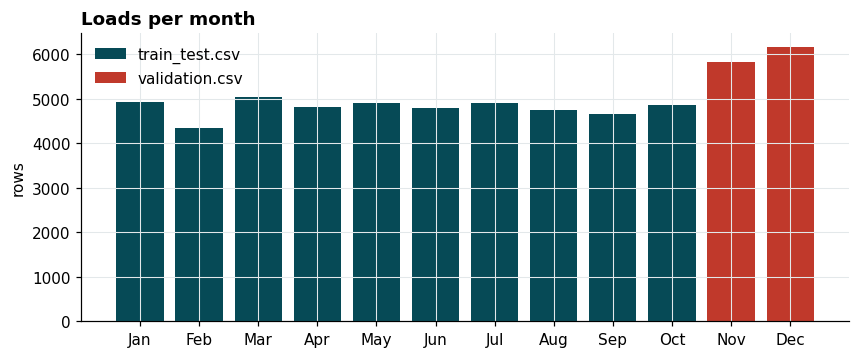

* template IDs == validation IDs: **True**; same row order: **True**  
* train/validation date overlap: **False**  
* gap between last training day and first validation day: **1 day(s)**

In [3]:
# Rows per month, train vs validation
monthly = pd.concat([train.assign(set="train"), valid.assign(set="validation")]).groupby([pd.Grouper(key="date", freq="MS"), "set"]).size().unstack(fill_value=0)
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(monthly.index.strftime("%b"), monthly["train"], color=TEAL, label="train_test.csv")
ax.bar(monthly.index.strftime("%b"), monthly["validation"], color=RED, label="validation.csv")
ax.set_title("Loads per month"); ax.set_ylabel("rows"); ax.legend(frameon=False)
save_fig(fig, P, "rows_per_month"); plt.show()

same_ids = set(template.load_id) == set(valid.load_id)
same_order = bool((template.load_id.values == valid.load_id.values).all())
display(Markdown(f"* template IDs == validation IDs: **{same_ids}**; same row order: **{same_order}**  \n"
                 f"* train/validation date overlap: **{train.date.max() >= valid.date.min()}**  \n"
                 f"* gap between last training day and first validation day: **{(valid.date.min() - train.date.max()).days} day(s)**"))

**Interpretation.** Training covers January-October 2025 (about 4,800 loads a month); validation covers November-December (about 6,000 a month) with no labels. The template holds exactly the validation IDs.

**Modelling implication.** There is **no date overlap and validation is entirely in the future**, so this is a *forecasting* problem. A random train/test split would let a model see same-day neighbours of every test row and give misleadingly good scores; validation must therefore move forward in time (notebook 3).

## 2. Are there missing or impossible values?

**Question.** Which columns have gaps, which values are physically impossible (negative weight, zero distance, duplicate IDs), and is the missingness random?

**Why it matters.** Each defect needs a deliberate decision (repair, ignore, or drop). The wrong choice either discards good rows or bakes errors into the model.

In [4]:
miss = pd.DataFrame({
    "train_missing": train.isna().sum(), "train_%": 100 * train.isna().mean(),
    "valid_missing": valid.isna().sum(), "valid_%": 100 * valid.isna().mean()})
display(miss[(miss.train_missing > 0) | (miss.valid_missing > 0)])

,train_missing,train_%,valid_missing,valid_%
market_index,374,0.7792,249.0000,2.0750
weight,300,0.6250,165.0000,1.3750


,positive rows,|negative rows|
count,"47,408.0000",292.0000
mean,"31,415.3587","31,724.1952"
std,"7,994.9030","8,262.5363"
min,"5,000.0000","5,000.0000"
25%,"25,922.0000","25,928.5000"
50%,"31,493.5000","31,821.5000"
75%,"37,063.0000","37,284.2500"
max,"47,500.0000","47,500.0000"


Two-sample KS test, |negative weight| vs positive weight: statistic = **0.041**, p = **0.697**  
Negative-weight rows: train **292**, validation **145**

,rpm,distance
neg,,
weight >= 0,2.1452,953.3500
weight < 0,2.1567,930.4500


neg,False,True
equipment,,
Dry Van,0.5670,0.5310
Flatbed,0.1820,0.2400
Reefer,0.2510,0.2290


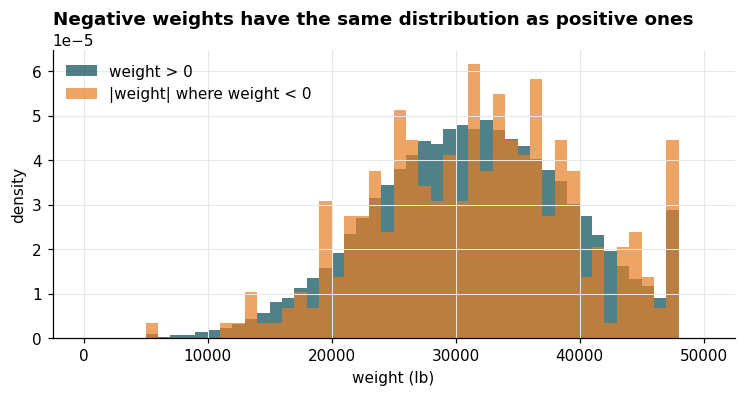

In [5]:
# --- Negative weight: genuinely different loads, or a sign error? ---
neg, pos = train[train.weight < 0], train[train.weight > 0]
w_cmp = pd.DataFrame({"positive rows": pos.weight.describe(), "|negative rows|": neg.weight.abs().describe()})
display(w_cmp)
ks = stats.ks_2samp(neg.weight.abs(), pos.weight)
display(Markdown(f"Two-sample KS test, |negative weight| vs positive weight: statistic = **{ks.statistic:.3f}**, p = **{ks.pvalue:.3f}**  \n"
                 f"Negative-weight rows: train **{len(neg)}**, validation **{(valid.weight < 0).sum()}**"))

# do negative rows look like other rows on the TARGET, once distance and equipment are accounted for?
tmp = clean_inputs(train).assign(rpm=lambda d: d.posted_rate / d.distance, neg=train.weight < 0)
display(tmp.groupby("neg")[["rpm", "distance"]].median().rename(index={False: "weight >= 0", True: "weight < 0"}))
display(pd.crosstab(tmp.equipment, tmp.neg, normalize="columns").round(3))

fig, ax = plt.subplots(figsize=(8, 3.4))
bins = np.linspace(0, 50000, 51)
ax.hist(pos.weight, bins=bins, density=True, alpha=0.7, color=TEAL, label="weight > 0")
ax.hist(neg.weight.abs(), bins=bins, density=True, alpha=0.7, color=ORANGE, label="|weight| where weight < 0")
ax.set_title("Negative weights have the same distribution as positive ones"); ax.set_xlabel("weight (lb)"); ax.set_ylabel("density"); ax.legend(frameon=False)
save_fig(fig, P, "negative_weight"); plt.show()

In [6]:
# --- Cap, zeros and other validity checks ---
aw = train.weight.abs()
checks = pd.Series({
    "duplicate load_id (train)": train.load_id.duplicated().sum(),
    "duplicate load_id (validation)": valid.load_id.duplicated().sum(),
    "duplicate feature rows ignoring load_id (train)": train.duplicated(subset=[c for c in train.columns if c != "load_id"]).sum(),
    "rows with |weight| == 47,500 (cap)": int((aw == 47500).sum()),
    "rows with |weight| > 47,500": int((aw > 47500).sum()),
    "rows with weight == 0": int((train.weight == 0).sum()),
    "distance <= 0": int((train.distance <= 0).sum()),
    "posted_rate <= 0": int((train.posted_rate <= 0).sum()),
    "pickup == delivery": int((train.pickup == train.delivery).sum()),
    "invalid dates": int(train.date.isna().sum() + valid.date.isna().sum()),
    "latitude outside [-90, 90]": int((~train.pickup_lat.between(-90, 90)).sum()),
    "equipment categories (train)": train.equipment.nunique(),
}, name="count")
display(checks.to_frame())

# --- Is missingness random? compare price level of rows with / without the gap ---
t = clean_inputs(train).assign(rpm=lambda d: d.posted_rate / d.distance)
rows = []
for col in ["weight", "market_index"]:
    m = t[col].isna()
    rows.append({"column": col, "n_missing": int(m.sum()),
                 "median rate/mile (missing)": t.loc[m, "rpm"].median(), "median rate/mile (present)": t.loc[~m, "rpm"].median(),
                 "p-value (Mann-Whitney)": stats.mannwhitneyu(t.loc[m, "rpm"], t.loc[~m, "rpm"]).pvalue})
display(pd.DataFrame(rows).set_index("column"))

,count
duplicate load_id (train),0
duplicate load_id (validation),0
duplicate feature rows ignoring load_id (train),0
"rows with |weight| == 47,500 (cap)",1204
"rows with |weight| > 47,500",0
rows with weight == 0,0
distance <= 0,0
posted_rate <= 0,0
pickup == delivery,0
invalid dates,0


,n_missing,median rate/mile (missing),median rate/mile (present),p-value (Mann-Whitney)
column,,,,
weight,300,2.1176,2.1456,0.2343
market_index,374,2.1209,2.1455,0.4582


**Interpretation.** *(see the numbers above)* Negative weights are not a different kind of load: their absolute values follow the same distribution as the positive weights (KS statistic near zero) and the rows are priced like all others. They are **sign errors**. Weight is also **capped at exactly 47,500 lb** (a spike in the histogram), and no distance, rate, ID or date is invalid. Missing weight and missing `market_index` are rare (under 1% in training, but about 1.4% and 2.1% in validation) and their rows are priced like the rest in training (Mann-Whitney p-values well above 0.05), so nothing suggests the gaps carry information. Note that **validation is somewhat messier than training**: sign errors in weight are about twice as frequent (145 of 12,000 = 1.2% vs 292 of 48,000 = 0.6%) and gaps are more common, so the cleaning must be applied identically to both files.

**Modelling implication.** `weight -> abs(weight)` (done by `common.clean_inputs`); missing weight stays `NaN` because the gradient-boosting model handles it natively; `market_index` gaps do not matter because the model only uses a **daily average** of the column. The cap is kept as is (a real limit, not an error).

*Caveat.* Absence of a significant difference is not proof of randomness, only that no pattern is visible at this sample size.

## 3. Do validation categories exist in training?

**Question.** Are the cities, equipment types, distances and weights in validation like those in training?

**Why it matters.** A model that memorises city names fails on a city it has never seen. The answer tells us whether we must rely on geography/distance instead of identities.

In [7]:
seen = set(train.pickup) | set(train.delivery)
valid_cities = set(valid.pickup) | set(valid.delivery)
unseen = sorted(valid_cities - seen)
touch_unseen = ~(valid.pickup.isin(seen) & valid.delivery.isin(seen))
train_routes = set(zip(train.pickup, train.delivery))
unseen_route = pd.Series([(a, b) not in train_routes for a, b in zip(valid.pickup, valid.delivery)])

display(Markdown(f"* cities in train: **{len(seen)}**, in validation: **{len(valid_cities)}**  \n"
                 f"* cities never seen in training: **{len(unseen)}** -> {unseen}  \n"
                 f"* validation rows touching an unseen city: **{touch_unseen.mean():.1%}** "
                 f"(pickup only {(~valid.pickup.isin(seen) & valid.delivery.isin(seen)).mean():.1%}, "
                 f"delivery only {(valid.pickup.isin(seen) & ~valid.delivery.isin(seen)).mean():.1%}, both {(~valid.pickup.isin(seen) & ~valid.delivery.isin(seen)).mean():.2%})  \n"
                 f"* validation rows whose exact (pickup, delivery) route never occurs in training: **{unseen_route.mean():.1%}**"))

coords = pd.concat([valid[["pickup", "pickup_lat", "pickup_lon"]].set_axis(["city", "lat", "lon"], axis=1),
                    valid[["delivery", "delivery_lat", "delivery_lon"]].set_axis(["city", "lat", "lon"], axis=1)]).drop_duplicates()
display(coords[coords.city.isin(unseen)].sort_values("city").reset_index(drop=True))
display(Markdown(f"Max number of distinct coordinate pairs for any single city (train+valid): **{pd.concat([train[['pickup','pickup_lat','pickup_lon']].set_axis(['city','lat','lon'],axis=1), coords]).drop_duplicates().groupby('city').size().max()}**"))

* cities in train: **64**, in validation: **72**  
* cities never seen in training: **8** -> ['Allentown', 'Charlotte', 'Chicago', 'Jackson', 'Knoxville', 'Laredo', 'Norfolk', 'San Diego']  
* validation rows touching an unseen city: **12.1%** (pickup only 6.0%, delivery only 6.0%, both 0.00%)  
* validation rows whose exact (pickup, delivery) route never occurs in training: **12.2%**

,city,lat,lon
0,Allentown,40.0168,-73.8089
1,Charlotte,34.6527,-81.4720
2,Chicago,40.5120,-86.8674
3,Jackson,32.0777,-90.9259
4,Knoxville,36.2572,-86.0254
5,Laredo,25.5000,-97.2268
6,Norfolk,37.1228,-75.8711
7,San Diego,32.0093,-116.8960


Max number of distinct coordinate pairs for any single city (train+valid): **1**

,train,validation
equipment,,
Dry Van,0.5667,0.5650
Reefer,0.2509,0.2542
Flatbed,0.1824,0.1807


,train median,valid median,KS statistic
feature,,,
distance,953.3000,953.6000,0.0072
weight,"31,496.0000","31,332.0000",0.0096
market_index,1.0558,0.9229,0.4832
quote_signal,2.0558,2.0512,0.0459


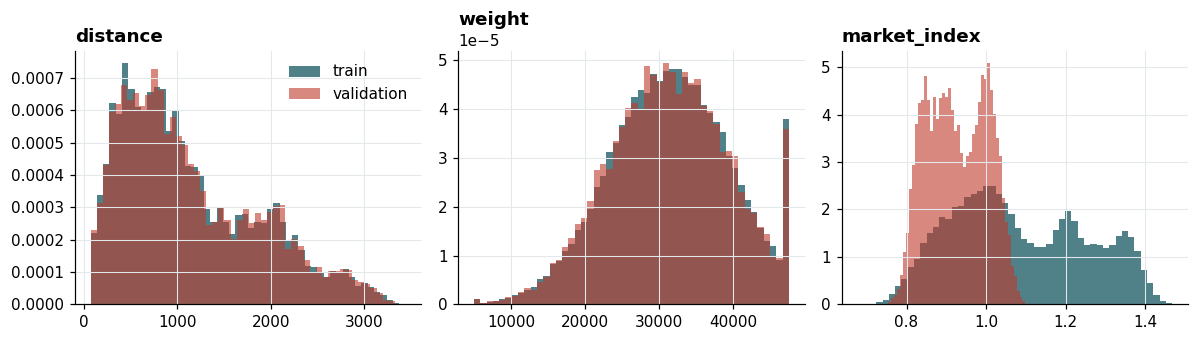

In [8]:
# Compare the feature distributions of the two periods
eq = pd.concat([train.equipment.value_counts(normalize=True).rename("train"), valid.equipment.value_counts(normalize=True).rename("validation")], axis=1)
display(eq)
rows = []
for col in ["distance", "weight", "market_index", "quote_signal"]:
    a, b = train[col].abs().dropna(), valid[col].abs().dropna()
    rows.append({"feature": col, "train median": a.median(), "valid median": b.median(), "KS statistic": stats.ks_2samp(a, b).statistic})
display(pd.DataFrame(rows).set_index("feature"))

fig, axes = plt.subplots(1, 3, figsize=(11, 3.2))
for ax, col in zip(axes, ["distance", "weight", "market_index"]):
    ax.hist(train[col].abs(), bins=50, density=True, alpha=0.7, color=TEAL, label="train")
    ax.hist(valid[col].abs(), bins=50, density=True, alpha=0.6, color=RED, label="validation")
    ax.set_title(col)
axes[0].legend(frameon=False); fig.tight_layout(); save_fig(fig, P, "train_vs_valid"); plt.show()

**Interpretation.** Eight validation cities never appear in training and they touch a noticeable share of validation rows (about 12% - see above), so for those loads the model must work from distance and coordinates. Each city has exactly one coordinate pair. Equipment mix, distance and weight look alike in the two periods. `market_index` shifts clearly (KS about 0.48: validation days sit lower, around 0.92 vs 1.06 median) while the overall distribution of `quote_signal` is nearly unchanged (KS about 0.05); both are time-varying and are examined in section 6. Unseen cities occur on **one side of a load only** (pickup or delivery, never both). The coordinates look **approximate** rather than exact (for example Chicago is listed at 40.5 N, -86.9 E, whereas the real city is near 41.9 N, -87.6 E - external knowledge, not derived from the data), so they behave as *regional indicators*, not precise geometry.

**Modelling implication.** *Do not* use city names (one-hot or target encoding). Use **distance + latitude/longitude** so unseen cities still get a sensible estimate, and **simulate** this in validation by holding cities out (notebook 3).

## 4. How does the target behave?

**Question.** What is the distribution of `posted_rate`, how does it relate to distance, equipment and the other columns, and is price per mile constant?

**Why it matters.** This decides the target transformation (raw dollars or log) and the shape of the distance term.

,posted_rate,distance,rpm
count,"48,000.0000","48,000.0000","48,000.0000"
mean,"2,373.9807","1,135.8567",2.2153
std,"1,486.4932",728.5644,0.5839
min,57.2200,70.0000,0.3337
1%,327.1688,121.8990,1.6735
25%,"1,251.5550",550.4000,1.9870
50%,"2,030.7600",953.3000,2.1453
75%,"3,330.7500","1,645.5250",2.3427
99%,"5,972.8340","3,029.3040",3.1769
max,"25,533.0000","3,439.8000",14.1253


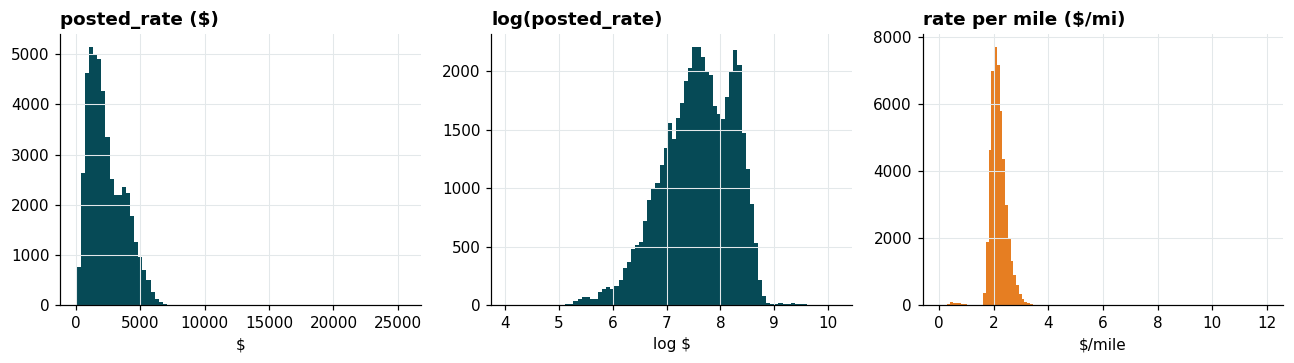

skewness of raw rate: **1.90**, of log rate: **-0.49**

In [9]:
tr = clean_inputs(train).assign(rpm=lambda d: d.posted_rate / d.distance)
display(tr[["posted_rate", "distance", "rpm"]].describe(percentiles=[.01, .25, .5, .75, .99]))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].hist(tr.posted_rate, bins=80, color=TEAL); axes[0].set_title("posted_rate ($)"); axes[0].set_xlabel("$")
axes[1].hist(np.log(tr.posted_rate), bins=80, color=TEAL); axes[1].set_title("log(posted_rate)"); axes[1].set_xlabel("log $")
axes[2].hist(tr.rpm, bins=np.linspace(0, 12, 120), color=ORANGE); axes[2].set_title("rate per mile ($/mi)"); axes[2].set_xlabel("$/mile")
fig.tight_layout(); save_fig(fig, P, "target_distribution"); plt.show()
display(Markdown(f"skewness of raw rate: **{stats.skew(tr.posted_rate):.2f}**, of log rate: **{stats.skew(np.log(tr.posted_rate)):.2f}**"))

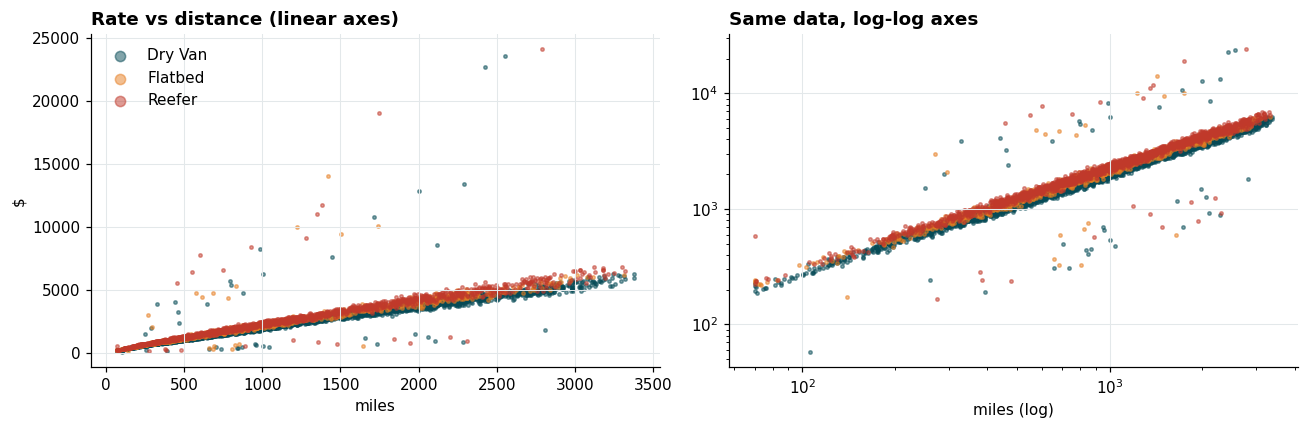

In [10]:
sample = tr.sample(6000, random_state=0)
colors = {"Dry Van": TEAL, "Flatbed": ORANGE, "Reefer": RED}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for eq_name, g in sample.groupby("equipment"):
    axes[0].scatter(g.distance, g.posted_rate, s=5, alpha=0.5, color=colors[eq_name], label=eq_name)
    axes[1].scatter(g.distance, g.posted_rate, s=5, alpha=0.5, color=colors[eq_name])
axes[0].set_title("Rate vs distance (linear axes)"); axes[0].set_xlabel("miles"); axes[0].set_ylabel("$"); axes[0].legend(frameon=False, markerscale=3)
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_title("Same data, log-log axes"); axes[1].set_xlabel("miles (log)")
fig.tight_layout(); save_fig(fig, P, "rate_vs_distance"); plt.show()

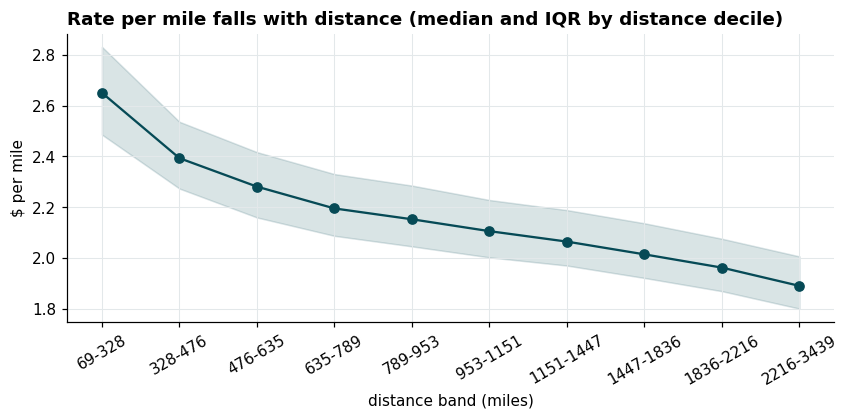

,R^2
log rate ~ distance,0.8523
log rate ~ log distance,0.9871
log rate ~ log distance + log distance^2,0.9872


In [11]:
# Is price per mile constant? Median and inter-quartile range by distance band
bands = pd.qcut(tr.distance, 10)
q = tr.groupby(bands, observed=True).rpm.quantile([.25, .5, .75]).unstack()
q.index = [f"{int(i.left)}-{int(i.right)}" for i in q.index]
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(q.index, q[0.5], color=TEAL, marker="o"); ax.fill_between(q.index, q[0.25], q[0.75], color=TEAL, alpha=0.15)
ax.set_title("Rate per mile falls with distance (median and IQR by distance decile)"); ax.set_ylabel("$ per mile"); ax.set_xlabel("distance band (miles)")
plt.xticks(rotation=30); save_fig(fig, P, "rate_per_mile_by_distance"); plt.show()

# How well do simple log-linear forms describe the (uncorrupted) rows? R^2 on log rate
dmi = daily_market_index(train, valid)
good = flag_label_outliers(tr, dmi)
y = np.log(tr.posted_rate[good].to_numpy()); ld = np.log(tr.distance[good].to_numpy())
def r2(cols):
    X = np.column_stack([np.ones(len(y)), *cols]); b = np.linalg.lstsq(X, y, rcond=None)[0]; return 1 - ((y - X @ b) ** 2).sum() / ((y - y.mean()) ** 2).sum()
display(pd.Series({"log rate ~ distance": r2([tr.distance[good]]), "log rate ~ log distance": r2([ld]),
                   "log rate ~ log distance + log distance^2": r2([ld, ld ** 2])}, name="R^2").to_frame())

,n,median_rate_per_mile,median_rate
equipment,,,
Dry Van,27202,2.0462,"1,953.0350"
Flatbed,8753,2.2197,"2,076.8100"
Reefer,12045,2.3115,"2,196.6700"


median rate-per-mile premium vs Dry Van: **Flatbed** +8.5%, **Reefer** +13.0%

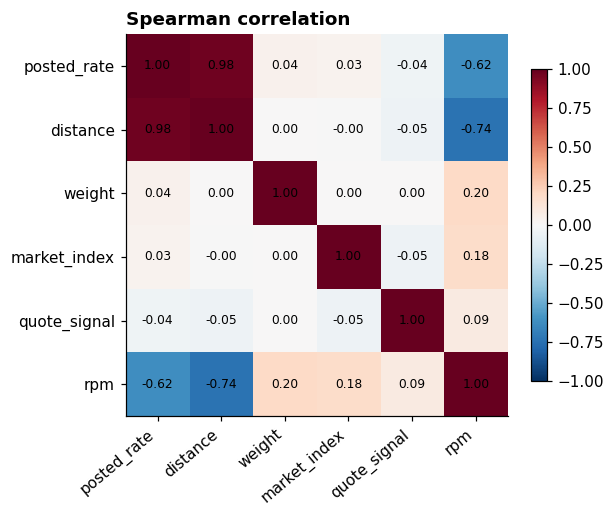

,pickup,delivery,distance,equipment,weight,posted_rate,rpm
14102,Buffalo,Bakersfield,"2,536.4000",Dry Van,"27,044.0000",846.4200,0.3337
25798,Albany,Reno,"2,894.3000",Dry Van,"32,383.0000",969.8300,0.3351
23043,Phoenix,Philadelphia,"2,983.4000",Dry Van,"37,692.0000","1,047.9100",0.3512
870,Tulsa,Baton Rouge,305.6000,Reefer,"26,447.0000","4,069.2400",13.3156
36609,Chattanooga,Atlanta,98.4000,Reefer,"22,226.0000","1,386.4200",14.0896
22254,Greensboro,Cincinnati,314.7000,Reefer,"36,485.0000","4,445.2300",14.1253


In [12]:
# Equipment, correlations, extremes
display(tr.groupby("equipment").agg(n=("rpm", "size"), median_rate_per_mile=("rpm", "median"), median_rate=("posted_rate", "median")))
premium = tr.groupby("equipment").rpm.median() / tr[tr.equipment == "Dry Van"].rpm.median() - 1
display(Markdown("median rate-per-mile premium vs Dry Van: " + ", ".join(f"**{k}** {v:+.1%}" for k, v in premium.items() if k != "Dry Van")))

cols = ["posted_rate", "distance", "weight", "market_index", "quote_signal", "rpm"]
corr = tr[cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(5.6, 4.6))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(cols)), cols, rotation=40, ha="right"); ax.set_yticks(range(len(cols)), cols)
for i in range(len(cols)):
    for j in range(len(cols)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Spearman correlation"); fig.colorbar(im, shrink=0.8); save_fig(fig, P, "spearman"); plt.show()

display(tr.sort_values("rpm").iloc[[0, 1, 2, -3, -2, -1]][["pickup", "delivery", "distance", "equipment", "weight", "posted_rate", "rpm"]])

**Interpretation.** Price is right-skewed in dollars and much more symmetric in logs. Price tracks distance almost one-for-one in rank (Spearman about 0.98) but **price per mile is not constant**: short hauls cost noticeably more per mile because price grows less than proportionally with distance (the elasticity of price to distance is about 0.87, i.e. below 1, rising slowly from about 0.84 at 150 miles to 0.90 at 3,000 miles; so the squared term adds almost nothing to R^2, 0.9871 to 0.9872, and is kept only as cheap flexibility). Reefer and Flatbed carry a premium over Dry Van. `weight`, `market_index` and `quote_signal` have rank correlations with the raw price of only about 0.04, 0.03 and -0.04, **but that does not make them useless**: distance swamps everything in a raw correlation, and the market effect is a *day-level* effect that we examine below. A few rows have implausible rates per mile (about $10+ or a few cents).

**Modelling implication.** Model **log(rate)** with **log(distance) and log(distance)^2**, plus equipment. Multiplicative effects (a 13% reefer premium applies to cheap and expensive loads alike) become additive and the error becomes relative. The implausible rows lead to the next question.

## 5. Are there potentially corrupted labels?

**Question.** After accounting for distance, equipment and the daily market level, do some `posted_rate` values deviate so strongly that they look like data errors rather than genuine price variation?

**Why it matters.** Training on mislabelled rows teaches the model wrong lessons and distorts error metrics. But dropping genuine hard cases would be just as harmful, so the evidence has to be convincing.

* flagged as corrupted: **677** of 48,000 rows (**1.41%**); too high: **340**, too low: **337**  
* residual sd of the good rows: **0.0401** (robust MAD-based sd 0.0413)  
* largest |residual| among kept rows: **0.167**;  smallest |residual| among flagged rows: **0.777**  
* implied price factor of flagged rows: **2.2x to 5.8x**

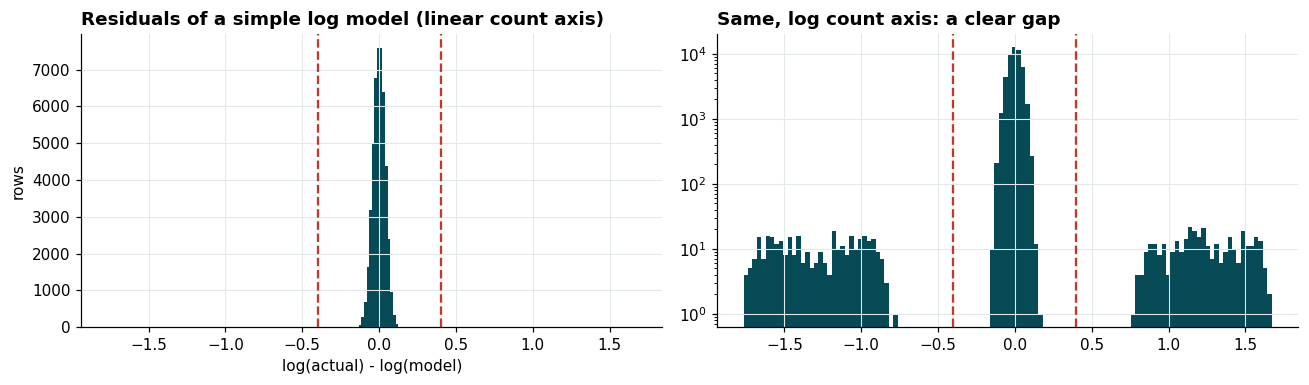

In [13]:
tr = clean_inputs(train)
keep = flag_label_outliers(tr, dmi)          # the exact function used in training
y = np.log(tr.posted_rate.to_numpy())
X = np.column_stack([np.ones(len(tr)), linear_features(tr, dmi)])
beta = np.linalg.lstsq(X[keep], y[keep], rcond=None)[0]
resid = y - X @ beta                          # log-residual of a SIMPLE model (no trees)

mad_sd = 1.4826 * np.median(np.abs(resid[keep] - np.median(resid[keep])))
display(Markdown(f"* flagged as corrupted: **{(~keep).sum()}** of {len(tr):,} rows (**{(~keep).mean():.2%}**); too high: **{(resid[~keep] > 0).sum()}**, too low: **{(resid[~keep] < 0).sum()}**  \n"
                 f"* residual sd of the good rows: **{resid[keep].std():.4f}** (robust MAD-based sd {mad_sd:.4f})  \n"
                 f"* largest |residual| among kept rows: **{np.abs(resid[keep]).max():.3f}**;  smallest |residual| among flagged rows: **{np.abs(resid[~keep]).min():.3f}**  \n"
                 f"* implied price factor of flagged rows: **{np.exp(np.abs(resid[~keep])).min():.1f}x to {np.exp(np.abs(resid[~keep])).max():.1f}x**"))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
axes[0].hist(resid, bins=200, color=TEAL); axes[0].set_title("Residuals of a simple log model (linear count axis)"); axes[0].set_xlabel("log(actual) - log(model)"); axes[0].set_ylabel("rows")
axes[1].hist(resid, bins=120, color=TEAL); axes[1].set_yscale("log"); axes[1].set_title("Same, log count axis: a clear gap")
for ax in axes:
    for s in (-OUTLIER_LOG_THRESHOLD, OUTLIER_LOG_THRESHOLD): ax.axvline(s, color=RED, ls="--")
fig.tight_layout(); save_fig(fig, P, "label_residuals"); plt.show()

In [14]:
# Is the result sensitive to the threshold?  (a single-pass count at several cut-offs)
sens = pd.DataFrame({"threshold |log residual| >": [0.15, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7]})
sens["rows flagged"] = [(np.abs(resid) > t).sum() for t in sens.iloc[:, 0]]
sens["% of train"] = 100 * sens["rows flagged"] / len(resid)
display(sens)

# Are flagged rows spread randomly, or concentrated somewhere (which would suggest a real pattern, not noise)?
flag = pd.Series(~keep, index=tr.index, name="flagged")
for name, grouper in [("equipment", tr.equipment), ("month", tr.date.dt.month), ("distance quintile", pd.qcut(tr.distance, 5, labels=False))]:
    ct = pd.crosstab(grouper, flag)
    chi = stats.chi2_contingency(ct)
    display(Markdown(f"flagged share by **{name}** - chi-square p = **{chi.pvalue:.3f}**"))
    display((ct[True] / ct.sum(axis=1)).rename("share flagged").to_frame().T.style.format("{:.2%}"))

,threshold |log residual| >,rows flagged,% of train
0,0.1500,679,1.4146
1,0.2000,677,1.4104
2,0.3000,677,1.4104
3,0.4000,677,1.4104
4,0.5000,677,1.4104
5,0.6000,677,1.4104
6,0.7000,677,1.4104


flagged share by **equipment** - chi-square p = **0.443**

equipment,Dry Van,Flatbed,Reefer
share flagged,1.35%,1.45%,1.51%


flagged share by **month** - chi-square p = **0.768**

date,1,2,3,4,5,6,7,8,9,10
share flagged,1.65%,1.31%,1.41%,1.37%,1.26%,1.32%,1.32%,1.43%,1.37%,1.65%


flagged share by **distance quintile** - chi-square p = **0.317**

distance,0,1,2,3,4
share flagged,1.58%,1.46%,1.43%,1.35%,1.23%


**Interpretation.** The residuals form two groups: a tight band (sd about 0.04 in log units, i.e. about 4%) and a small set at about **2-6x too high or too low** (implied factor range printed above) with **no rows in between**. That gap is what makes a threshold defensible: thresholds anywhere from about 0.2 to 0.7 flag (almost) the same rows. The flagged rows are spread over equipment, months and distances without a strong pattern, and they are both inflated and deflated by similar factors. Both observations favour *random data-entry or scaling errors* over genuine market behaviour.

**Critical caveats (important, not cosmetic):**
1. The flag is **derived from the labels**, so it can be applied to training data only; validation labels are unavailable, so nothing can be filtered there, and any such errors in the validation labels will inflate Spotter's error metrics regardless of model quality.
2. The method only detects **large** corruption (above roughly 1.5x). Small errors stay undetected.
3. It is somewhat circular (a model fit on data containing outliers defines the residuals); the two-pass fit mitigates this, and the wide gap makes it robust.
4. Here the flags use **all** training rows (exploration). In modelling (notebook 3) the flags are recomputed **inside each training fold only**.

**Modelling implication.** Drop flagged rows from *training*; report metrics on trusted rows and on all rows separately.

## 6. How do the market variables behave over time?

**Question.** Is `market_index` one value per day plus noise? How do `market_index` and `quote_signal` evolve, and how do Nov-Dec compare with Jan-Oct?

**Why it matters.** These are the only time-varying inputs. If one is a stable daily driver we can use it; if one is a regime-switching proxy it may fail outside the training period.

,share of variance between days,typical within-day sd,range of daily mean
market_index,0.9776,0.0249,0.6350
quote_signal,0.1737,0.2537,0.5753


rows per day: min **115**, median **161**, max **227**; days covered: **365** of 365

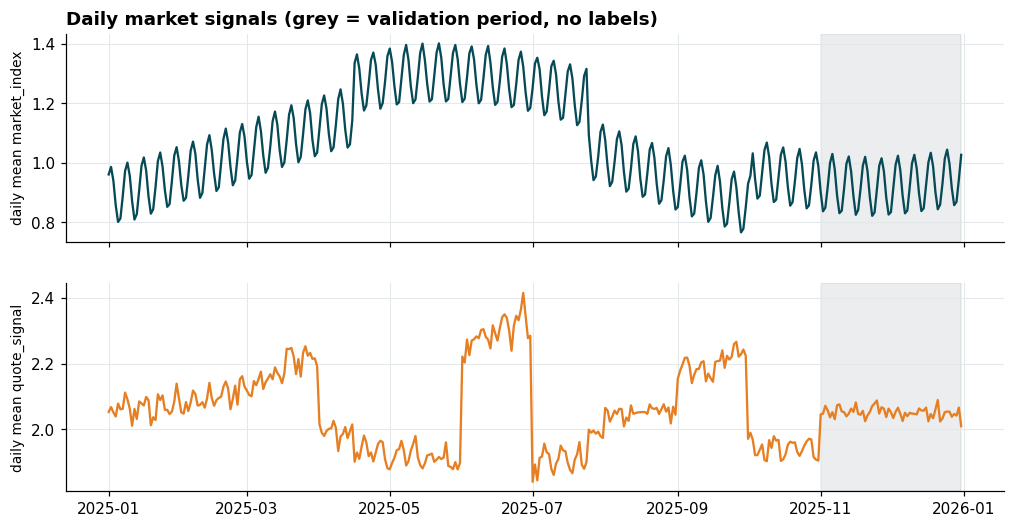

In [15]:
both = pd.concat([train, valid])
daily = both.groupby("date").agg(dmi=("market_index", "mean"), dqs=("quote_signal", "mean"), n=("market_index", "size"),
                                 mi_sd_within=("market_index", "std"), qs_sd_within=("quote_signal", "std"))

# How much of each column's variance is BETWEEN days (a daily level) versus WITHIN a day (noise)?
def between_share(col):
    g = both.groupby("date")[col]
    total = both[col].var(); within = (both[col] - g.transform("mean")).var()
    return 1 - within / total
display(pd.DataFrame({"share of variance between days": {"market_index": between_share("market_index"), "quote_signal": between_share("quote_signal")},
                      "typical within-day sd": {"market_index": daily.mi_sd_within.mean(), "quote_signal": daily.qs_sd_within.mean()},
                      "range of daily mean": {"market_index": daily.dmi.max() - daily.dmi.min(), "quote_signal": daily.dqs.max() - daily.dqs.min()}}))
display(Markdown(f"rows per day: min **{daily.n.min()}**, median **{int(daily.n.median())}**, max **{daily.n.max()}**; days covered: **{len(daily)}** of {(daily.index.max() - daily.index.min()).days + 1}"))

fig, axes = plt.subplots(2, 1, figsize=(11, 5.4), sharex=True)
for ax, col, color, label in [(axes[0], "dmi", TEAL, "daily mean market_index"), (axes[1], "dqs", ORANGE, "daily mean quote_signal")]:
    ax.plot(daily.index, daily[col], color=color, lw=1.5)
    ax.axvspan(valid.date.min(), valid.date.max(), color=GREY, alpha=0.15); ax.set_ylabel(label, fontsize=9)
axes[0].set_title("Daily market signals (grey = validation period, no labels)")
save_fig(fig, P, "daily_signals"); plt.show()

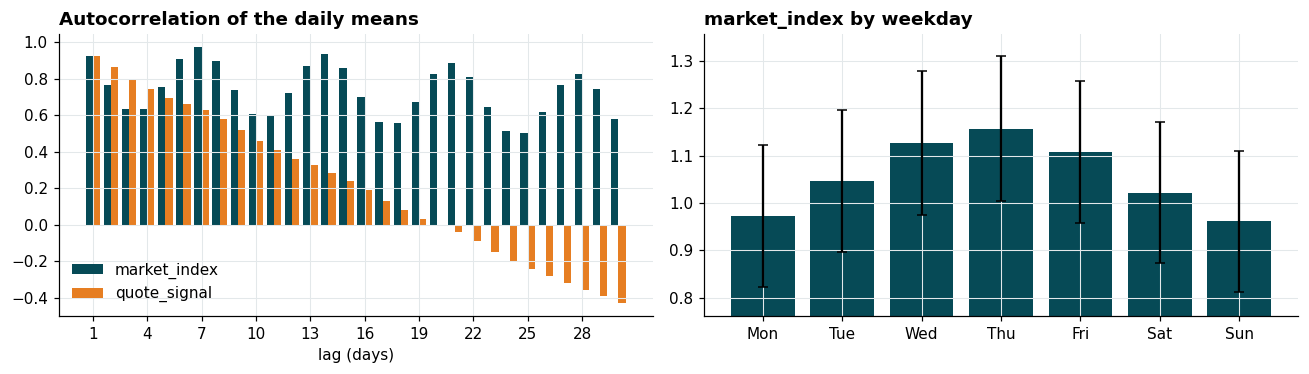

market_index autocorrelation: lag 1 = **0.93**, lag 7 = **0.97**, lag 3 = **0.64**

,dmi_mean,dmi_min,dmi_max,dqs_mean,dqs_sd,dqs_min,dqs_max
date,,,,,,,
1,0.9269,0.8019,1.0528,2.0683,0.0295,2.0108,2.1390
2,0.9974,0.8728,1.1306,2.0975,0.0321,2.0477,2.1615
3,1.0738,0.9469,1.2100,2.1797,0.0447,2.1007,2.2528
4,1.2086,1.0393,1.3709,1.9627,0.0401,1.8817,2.0257
5,1.3001,1.1964,1.4016,1.9135,0.0271,1.8777,1.9797
6,1.2800,1.1751,1.3928,2.2957,0.0462,2.2031,2.4153
7,1.2001,0.9421,1.3534,1.9228,0.0463,1.8400,1.9989
8,0.9800,0.8434,1.1060,2.0519,0.0165,2.0088,2.0762
9,0.8929,0.7666,1.0243,2.2002,0.0332,2.1407,2.2663


In [16]:
# Autocorrelation and weekly pattern
lags = range(1, 31)
acf = pd.DataFrame({"market_index": [daily.dmi.autocorr(l) for l in lags], "quote_signal": [daily.dqs.autocorr(l) for l in lags]}, index=list(lags))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
w = 0.4; x = np.arange(len(acf))
axes[0].bar(x - w / 2, acf.market_index, w, color=TEAL, label="market_index"); axes[0].bar(x + w / 2, acf.quote_signal, w, color=ORANGE, label="quote_signal")
axes[0].set_xticks(x[::3], acf.index[::3]); axes[0].set_xlabel("lag (days)"); axes[0].set_title("Autocorrelation of the daily means"); axes[0].legend(frameon=False)
dow = daily.dmi.groupby(daily.index.dayofweek).agg(["mean", "std"])
axes[1].bar(["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"], dow["mean"], yerr=dow["std"], color=TEAL, capsize=3)
axes[1].set_ylim(dow["mean"].min() - 0.2, dow["mean"].max() + 0.2); axes[1].set_title("market_index by weekday")
fig.tight_layout(); save_fig(fig, P, "acf_and_weekday"); plt.show()
display(Markdown(f"market_index autocorrelation: lag 1 = **{acf.loc[1, 'market_index']:.2f}**, lag 7 = **{acf.loc[7, 'market_index']:.2f}**, lag 3 = **{acf.loc[3, 'market_index']:.2f}**"))

# Monthly regime table
month_tbl = daily.groupby(daily.index.month).agg(dmi_mean=("dmi", "mean"), dmi_min=("dmi", "min"), dmi_max=("dmi", "max"),
                                                 dqs_mean=("dqs", "mean"), dqs_sd=("dqs", "std"), dqs_min=("dqs", "min"), dqs_max=("dqs", "max"))
display(month_tbl)

**Interpretation.**
* `market_index`: almost all its variance is **between days**; within a day the rows differ only by small noise. So it is *one daily level* observed with noise, and the **daily average** is a clean estimate. It has a strong **7-day cycle** (autocorrelation at lag 7 far above lag 3) and a visible weekday pattern. In Nov-Dec it stays inside the range seen in training, so no extrapolation in the index itself is needed.
* `quote_signal`: noisy within a day (only about 17% of its variance is between days) and it moves between **regimes** (about 2.3 in June, 1.9 in July, 2.2 in September). In Nov-Dec it is **flat** (about 2.05, daily sd about 0.016). This is *not* out of range for the training data: **August has the same level and spread**. So the case against `quote_signal` is *not* that Nov-Dec is unprecedented, but that its relation to price looks unstable (section 7) and that it may be a proxy of something else.

**Modelling implication.** Use the daily mean `market_index` (computed from *features* only). Treat `quote_signal` as suspect; section 7 tests whether it relates to price in a stable way, and notebook 3 tests it with an ablation. Also note the clean **weekly cycle** of `market_index`: it will be visible in the December chart.

## 7. What explains day-to-day changes in price?

**Question.** After removing distance, equipment, geography and weight effects, what is left in the *daily average* price level, and what does it correlate with?

**Why it matters.** This is where forecastable structure beyond the load's own attributes could be hiding (market level, drift, calendar effects).

,coefficient (log-rate units)
log_distance,0.7449
log_distance^2,0.0096
flatbed,0.0802
reefer,0.1215
daily_market_index,0.1425
trend (per 100 days),0.0197
quarter_end_ramp,0.0389


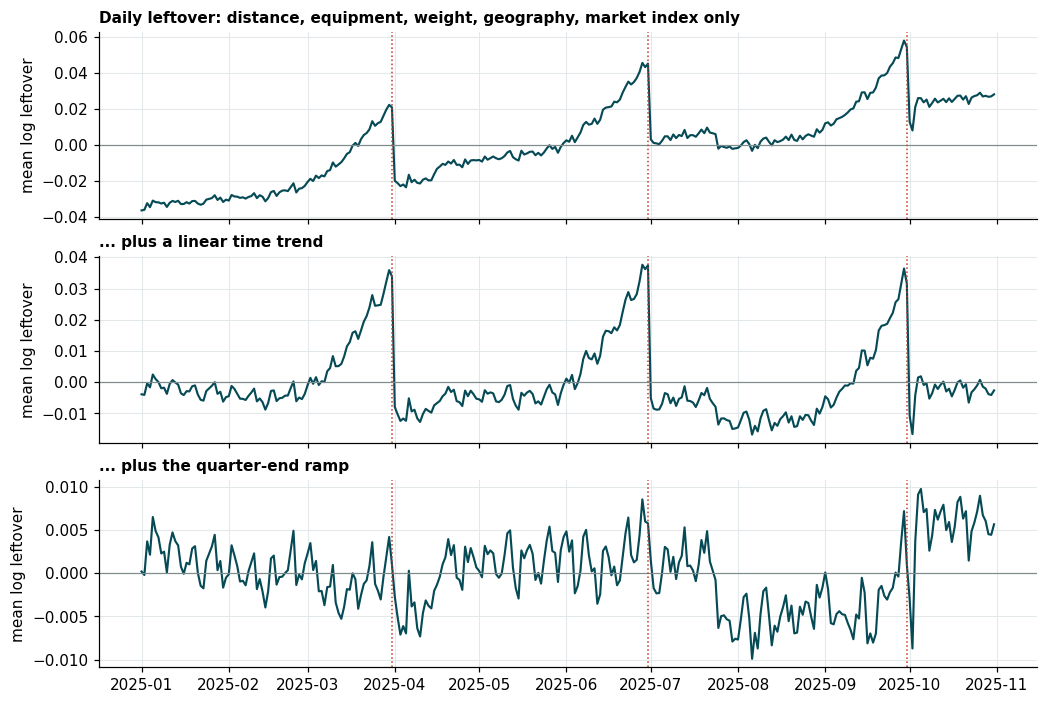

sd of daily leftover: no time terms **0.0214**, + trend **0.0115**, + ramp **0.0040**;  lag-1 autocorrelation: **0.98 / 0.91 / 0.80**

In [17]:
# In-sample diagnostic models. They contain NO calendar terms beyond what is stated, so the leftovers show what is still missing.
tr = clean_inputs(train); ok = flag_label_outliers(tr, dmi)
kept = tr[ok].copy()
def daily_leftover(**opts):
    m = FreightRateModel(dmi, **opts).fit(train, drop_outliers=True)
    return np.log(kept.posted_rate) - np.log(m.predict(kept)), m
kept["res_none"], m_none = daily_leftover(use_trend=False, use_ramp=False)
kept["res_trend"], m_trend = daily_leftover(use_trend=True, use_ramp=False)
kept["res_full"], m_full = daily_leftover(use_trend=True, use_ramp=True)

names = ["log_distance", "log_distance^2", "flatbed", "reefer", "daily_market_index", "trend (per 100 days)", "quarter_end_ramp"]
display(pd.DataFrame({"coefficient (log-rate units)": m_full.linear_.coef_ / m_full.sd_}, index=names))

d = kept.groupby("date")[["res_none", "res_trend", "res_full"]].mean()
fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True)
for ax, col, title in [(axes[0], "res_none", "Daily leftover: distance, equipment, weight, geography, market index only"),
                       (axes[1], "res_trend", "... plus a linear time trend"), (axes[2], "res_full", "... plus the quarter-end ramp")]:
    ax.plot(d.index, d[col], color=TEAL, lw=1.4); ax.axhline(0, color=GREY, lw=0.8); ax.set_title(title, fontsize=10); ax.set_ylabel("mean log leftover")
    for q in ("2025-03-31", "2025-06-30", "2025-09-30"): ax.axvline(pd.Timestamp(q), color=RED, ls=":", lw=1)
save_fig(fig, P, "daily_leftover"); plt.show()
display(Markdown(f"sd of daily leftover: no time terms **{d.res_none.std():.4f}**, + trend **{d.res_trend.std():.4f}**, + ramp **{d.res_full.std():.4f}**;  "
                 f"lag-1 autocorrelation: **{d.res_none.autocorr(1):.2f} / {d.res_trend.autocorr(1):.2f} / {d.res_full.autocorr(1):.2f}**"))

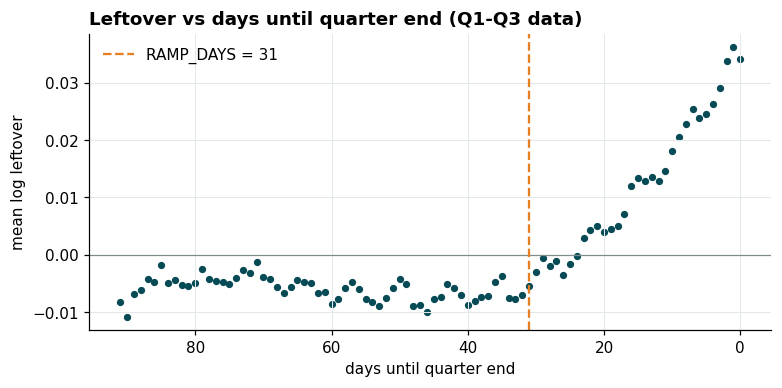

,quarter-end month,"mean leftover, last 10 days","mean leftover, earlier days",late - early
month,,,,
1,False,-0.0035,-0.0014,-0.0022
2,False,-0.0042,-0.0042,-0.0000
3,True,0.0272,0.0041,0.0231
4,False,-0.0041,-0.0098,0.0056
5,False,-0.0042,-0.0047,0.0005
6,True,0.0290,0.0059,0.0230
7,False,-0.0103,-0.0059,-0.0045
8,False,-0.0114,-0.0125,0.0011
9,True,0.0239,-0.0006,0.0246


average (last 10 days - earlier days): quarter-end months **+0.0236**, other months **+0.0002**

In [18]:
# Quarter-end effect (leftover after the trend, before the ramp) by days remaining in the quarter
kept["dtq"] = days_to_quarter_end(kept.date)
by_dtq = kept.groupby("dtq").res_trend.mean()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.scatter(by_dtq.index, by_dtq.values, s=14, color=TEAL); ax.invert_xaxis(); ax.axhline(0, color=GREY, lw=0.8)
ax.axvline(RAMP_DAYS, color=ORANGE, ls="--", label=f"RAMP_DAYS = {RAMP_DAYS}"); ax.legend(frameon=False)
ax.set_title("Leftover vs days until quarter end (Q1-Q3 data)"); ax.set_xlabel("days until quarter end"); ax.set_ylabel("mean log leftover")
save_fig(fig, P, "quarter_end_ramp"); plt.show()

# Critical check: is this a QUARTER-end effect, or just a month-end effect?
kept["dtm"] = (kept.date.dt.to_period("M").dt.end_time.dt.normalize() - kept.date).dt.days
kept["month"] = kept.date.dt.month
rows = []
for mth, g in kept.groupby("month"):
    late = g[g.dtm <= 10].res_trend.mean(); early = g[g.dtm >= 15].res_trend.mean()
    rows.append({"month": mth, "quarter-end month": mth in (3, 6, 9), "mean leftover, last 10 days": late, "mean leftover, earlier days": early, "late - early": late - early})
me = pd.DataFrame(rows).set_index("month"); display(me)
display(Markdown(f"average (last 10 days - earlier days): quarter-end months **{me[me['quarter-end month']]['late - early'].mean():+.4f}**, other months **{me[~me['quarter-end month']]['late - early'].mean():+.4f}**"))

In [19]:
# Is quote_signal a stable driver? Correlation of its daily mean with the daily leftover, by month
dq = daily.dqs.reindex(d.index)
byq = pd.DataFrame({"corr(daily quote_signal, leftover)": {m: np.corrcoef(dq[d.index.month == m], d.res_trend[d.index.month == m])[0, 1] for m in range(1, 11)},
                    "mean daily quote_signal": {m: dq[d.index.month == m].mean() for m in range(1, 11)}})
display(byq)
display(Markdown(f"overall corr(daily quote_signal, leftover after trend) = **{np.corrcoef(dq, d.res_trend)[0, 1]:.2f}**; "
                 f"months with positive correlation: **{(byq.iloc[:, 0] > 0).sum()}**, negative: **{(byq.iloc[:, 0] < 0).sum()}**"))

,"corr(daily quote_signal, leftover)",mean daily quote_signal
1,-0.4532,2.0683
2,-0.1292,2.0975
3,0.6976,2.1797
4,-0.4374,1.9627
5,0.4071,1.9135
6,0.6007,2.2957
7,-0.4734,1.9228
8,-0.3540,2.0519
9,0.6019,2.2002
10,-0.1180,1.9429


overall corr(daily quote_signal, leftover after trend) = **0.68**; months with positive correlation: **4**, negative: **6**

**Interpretation.**
* With only distance, equipment, weight, geography and the daily market index in the model, the *daily* leftover is still strongly autocorrelated and **drifts upward** through the year; a simple linear trend removes most of that.
* What remains is a **sawtooth**: the leftover rises over the final weeks of **March, June and September** and falls back right after quarter-end. Plotted against days until quarter-end it is an increasing ramp of a few percent over about the last month. The month-end check is the important control: the same late-month rise is **not** seen in the non-quarter-end months, which supports a *quarter*-specific effect rather than a generic month-end effect.
* The relation of `quote_signal` with the leftover **changes sign from month to month** (positive in 4 months, negative in 6), yet pooled over the year it correlates **+0.68** with the leftover. The pooled figure arises because `quote_signal` is *high in the same quarter-end months* where the leftover is high. That is exactly why it can look predictive without being a stable driver - and it raises a question we cannot settle from the data (see caveat 4).

**Critical caveats.**
1. These are **in-sample diagnostics on all ten months**; notebook 3 tests the ramp and trend out-of-sample.
2. A ramp supported by **three quarter-ends** is a small sample. And the training data contain only **October** of Q4, so applying the ramp to December is an **extrapolation of the calendar pattern**.
3. **Trend vs. annual seasonality cannot be separated** with 10 months of one year: the upward drift could be partly a seasonal cycle. For a 2-month extension the practical difference is small, but it is an assumption (quantified in notebook 4).
4. **An unresolved alternative explanation.** `quote_signal` is high in March, June and September, i.e. it co-moves with the quarter-end ramp. Two stories fit the training data: (a) the ramp is a calendar effect and `quote_signal` is a separate decoy that happens to coincide with it; (b) `quote_signal` is partly a *symptom* of the same quarter-end mechanism. In December `quote_signal` is flat. Under (a) the December ramp should still occur; under (b) it might not. Training data cannot distinguish them. The December chart therefore carries a real, disclosed risk of up to about 4% at month-end (quantified in notebook 4).

**Modelling implication.** Add (a) a linear `days since 2025-01-01` term, (b) a `days_to_quarter_end` ramp, both in the **linear** part of the model so they can extrapolate; and do **not** use `quote_signal`.

## 8. What do the December chart inputs require?

**Question.** What does `december_chart_inputs.csv` contain, which model inputs are missing from it, and can they be obtained without labels?

**Why it matters.** The chart rows have six columns but the model also needs coordinates and the daily market index. Whatever we add must be legitimate at prediction time.

In [20]:
display(december.head(3))
fixed = {c: december[c].nunique() for c in ["pickup", "delivery", "distance", "equipment", "weight"]}
display(Markdown(f"distinct values per fixed column: **{fixed}**; dates: **{december.date.min().date()} to {december.date.max().date()}** ({december.date.nunique()} unique); predicted_rate present: **{december.predicted_rate.notna().any()}**"))

model_inputs_needed = {"pickup_lat/lon, delivery_lat/lon": "look up by city name (each city has exactly one pair in train+valid)",
                       "daily market index": "mean of market_index over validation.csv rows with the same date (a FEATURE, no label)",
                       "days since Jan 1 / days to quarter end": "computed from the date"}
display(pd.Series(model_inputs_needed, name="how it is obtained").to_frame())

cities_known = set(train.pickup) | set(train.delivery) | set(valid.pickup) | set(valid.delivery)
chart_dates = valid[valid.date.isin(december.date)].groupby("date").market_index.agg(rows="size", daily_mean="mean")
dec_view = chart_dates.assign(days_since_Jan1=lambda x: (x.index - pd.Timestamp("2025-01-01")).days,
                              days_to_quarter_end=lambda x: days_to_quarter_end(pd.Series(x.index)),
                              ramp=lambda x: np.clip(1 - x.days_to_quarter_end / RAMP_DAYS, 0, 1))
both_known = {"Lexington", "Fort Wayne"} <= cities_known
oct_dtq = days_to_quarter_end(train.date[train.date.dt.month == 10])
oct_max_ramp = float(np.clip(1 - oct_dtq / RAMP_DAYS, 0, 1).max())
display(Markdown(f"* both lane cities known: **{both_known}**  \n"
                 f"* every December date has validation rows (min rows/day **{chart_dates.rows.min()}**), so the daily index is estimated from at least that many rows  \n"
                 f"* latest training day = day **{(train.date.max() - pd.Timestamp('2025-01-01')).days}**; December reaches day **{dec_view.days_since_Jan1.max()}** (the trend term is extrapolated)  \n"
                 f"* largest ramp value seen in Q4 training data (October): **{oct_max_ramp:.2f}**; in December the ramp rises from **{dec_view.ramp.iloc[0]:.2f}** to **{dec_view.ramp.iloc[-1]:.2f}**"))
display(dec_view.head(5)); display(dec_view.tail(3))

,pickup,delivery,distance,equipment,weight,date,predicted_rate
0,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-01,NaN
1,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-02,NaN
2,Lexington,Fort Wayne,360,Dry Van,32000,2025-12-03,NaN


distinct values per fixed column: **{'pickup': 1, 'delivery': 1, 'distance': 1, 'equipment': 1, 'weight': 1}**; dates: **2025-12-01 to 2025-12-31** (31 unique); predicted_rate present: **False**

,how it is obtained
"pickup_lat/lon, delivery_lat/lon",look up by city name (each city has exactly on...
daily market index,mean of market_index over validation.csv rows ...
days since Jan 1 / days to quarter end,computed from the date


* both lane cities known: **True**  
* every December date has validation rows (min rows/day **163**), so the daily index is estimated from at least that many rows  
* latest training day = day **303**; December reaches day **364** (the trend term is extrapolated)  
* largest ramp value seen in Q4 training data (October): **0.00**; in December the ramp rises from **0.03** to **1.00**

,rows,daily_mean,days_since_Jan1,days_to_quarter_end,ramp
date,,,,,
2025-12-01,203,0.8349,334,30,0.0323
2025-12-02,217,0.9147,335,29,0.0645
2025-12-03,213,0.9941,336,28,0.0968
2025-12-04,202,1.0240,337,27,0.1290
2025-12-05,185,0.9751,338,26,0.1613


,rows,daily_mean,days_since_Jan1,days_to_quarter_end,ramp
date,,,,,
2025-12-29,191,0.8696,362,2,0.9355
2025-12-30,210,0.9440,363,1,0.9677
2025-12-31,193,1.0273,364,0,1.0000


**Interpretation.** The December file fixes the lane (Lexington -> Fort Wayne, 360 mi, Dry Van, 32,000 lb) and varies only the date. Its two cities are known. The coordinates can be looked up; the daily market index can be obtained legitimately from the **features** of validation rows on each date, and every December date has hundreds of such rows.

**Modelling implication.** The December curve is driven only by date: the weekly market-index cycle, the extrapolated linear trend, and the quarter-end ramp (which climbs from 0 to 1 across December). All three are *assumptions about the future* and must be disclosed alongside the chart (sensitivity in notebook 4).

## Conclusion: findings -> decisions

| Finding | Evidence strength | Decision |
|---|---|---|
| Validation is entirely after training | Certain (dates) | Forward-in-time validation only |
| 8 unseen validation cities (~12% of rows) | Certain | Distance + coordinates, no city identities; simulate in CV |
| Negative weights are sign errors | Strong (same distribution) | `abs(weight)` |
| Weight capped at 47,500; small random gaps | Strong | Keep cap; NaN handled by trees |
| Rate is a curved function of distance | Strong | log target, log-distance and its square |
| ~1.4% of training labels corrupted (about 2-6x off) | Strong (clear gap, threshold-insensitive); detection is label-based | Drop from training only; report clean *and* all-label metrics |
| `market_index` is a daily level with a weekly cycle | Strong | Daily mean from features |
| Upward drift in daily price level | Moderate (cannot be separated from seasonality) | Linear trend term in the linear part |
| Quarter-end ramp | Moderate-strong for Q1-Q3 (3 of 3 quarter-ends, absent in other months); **unverified for Q4** | Ramp feature; tested out-of-sample in notebook 3; December risk disclosed |
| `quote_signal`: unstable sign by month, co-moves with the ramp, flat in Nov-Dec (similar to August) | Moderate | Exclude; ablation in notebook 3 |
| December = pure extrapolation in date | Certain | Disclose assumptions; sensitivity in notebook 4 |

**Next:** `02_feature_engineering.ipynb` turns these decisions into the production feature pipeline.